## NB11 — Validação com Dados Sintéticos

**Entrada:** `data/load/dataset_ml_model.csv` — 76.218 linhas × 25 colunas  
**Saída:** `data/output/recall_sinteticos.csv` — recall por modelo e perfil de anomalia

---
### 0. Imports e Configuração

In [23]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

RANDOM_STATE  = 42
CONTAMINATION = 0.01
N_SINTETICOS  = 500

np.random.seed(RANDOM_STATE)
os.makedirs('data/output', exist_ok=True)
print('Setup OK')

Setup OK


---
### 1. Carregamento e Preparação do Dataset Real

In [24]:
df_full = pd.read_csv('data/load/dataset_ml_model.csv')

identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_ids  = df_full[identificadores].copy()
df_feat = df_full.drop(columns=identificadores).copy()

feature_cols = df_feat.columns.tolist()

print(f'Shape: {df_feat.shape}')
print(f'Features ({len(feature_cols)}): {feature_cols}')

Shape: (76218, 20)
Features (20): ['desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral']


In [25]:
medians = df_feat[feature_cols].median().to_dict()
print('Medianas das features:')
for k, v in medians.items():
    print(f'  {k:35s}: {v}')

Medianas das features:
  desvio_item_estimado               : -0.1666666666666667
  n_propostas_item                   : 1.0
  fornecedor_unico                   : 1.0
  ano                                : 2024.0
  mes                                : 8.0
  trimestre                          : 3.0
  dia_semana                         : 2.0
  dias_para_eleicao                  : 138.0
  ano_eleitoral                      : 1.0
  pre_eleitoral_180d                 : 1.0
  fornecedor_fora_pe                 : 1.0
  tipo_fornecedor                    : 1.0
  idade_empresa_anos                 : 8.659822039698836
  empresa_nova                       : 0.0
  opcao_pelo_mei                     : 0.0
  opcao_pelo_simples                 : 0.0
  modalidadeNome                     : 4.0
  porte                              : 1.0
  cnae_fiscal                        : 4645101.0
  descricao_situacao_cadastral       : 0.0


---
### 2. Geração dos Perfis Sintéticos

In [26]:
# sobrescreve apenas os campos anômalos
def base_record():
    return {k: v for k, v in medians.items()}

sinteticos = []

#### P1 — Superfaturamento Extremo

In [27]:
for _ in range(N_SINTETICOS):
    r = base_record()
    r['desvio_item_estimado'] = np.random.uniform(2.5, 10.0)
    r['_perfil']              = 'P1_Superfaturamento'
    sinteticos.append(r)

print(f'P1 gerado: {N_SINTETICOS} registros')

P1 gerado: 500 registros


#### P2 — Empresa Fantasma

In [28]:
for _ in range(N_SINTETICOS):
    r = base_record()
    r['empresa_nova']                   = 1
    r['idade_empresa_anos']             = np.random.uniform(0.01, 0.3)
    r['descricao_situacao_cadastral']   = 0   # inapta/cancelada
    r['desvio_item_estimado']           = np.random.uniform(1.5, 3.0)
    r['_perfil']                        = 'P2_Empresa_Fantasma'
    sinteticos.append(r)

print(f'P2 gerado: {N_SINTETICOS} registros')

P2 gerado: 500 registros


#### P3 — Concentração Eleitoral

In [29]:
for _ in range(N_SINTETICOS):
    r = base_record()
    r['pre_eleitoral_180d']   = 1
    r['ano_eleitoral']        = 1
    r['dias_para_eleicao']    = np.random.randint(1, 30)
    r['desvio_item_estimado'] = np.random.uniform(1.5, 3.0)
    r['_perfil']              = 'P3_Concentracao_Eleitoral'
    sinteticos.append(r)

print(f'P3 gerado: {N_SINTETICOS} registros')

P3 gerado: 500 registros


#### P4 — Fornecedor Irregular de Fora do Estado

In [30]:
for _ in range(N_SINTETICOS):
    r = base_record()
    r['fornecedor_fora_pe']             = 1
    r['descricao_situacao_cadastral']   = 0
    r['desvio_item_estimado']           = np.random.uniform(1.5, 3.0)
    r['_perfil']                        = 'P4_Fornecedor_Irregular'
    sinteticos.append(r)

print(f'P4 gerado: {N_SINTETICOS} registros')

P4 gerado: 500 registros


#### P5 — Perfil Combinado (Todos Ps)

In [31]:
for _ in range(N_SINTETICOS):
    r = base_record()
    r['desvio_item_estimado']           = np.random.uniform(3.0, 10.0)
    r['empresa_nova']                   = 1
    r['idade_empresa_anos']             = np.random.uniform(0.01, 0.3)
    r['descricao_situacao_cadastral']   = 0
    r['pre_eleitoral_180d']             = 1
    r['ano_eleitoral']                  = 1
    r['dias_para_eleicao']              = np.random.randint(1, 30)
    r['fornecedor_fora_pe']             = 1
    r['_perfil']                        = 'P5_Combinado'
    sinteticos.append(r)

print(f'P5 gerado: {N_SINTETICOS} registros')
print(f'\nTotal sintéticos: {len(sinteticos)}')

P5 gerado: 500 registros

Total sintéticos: 2500


---
### 3. Construção do Dataset Combinado

In [32]:
df_sint = pd.DataFrame(sinteticos)
perfil_col = df_sint.pop('_perfil')  

df_sint = df_sint[feature_cols]

df_real_flag = df_feat.copy()
df_real_flag['_sintetico'] = False
df_real_flag['_perfil']    = 'real'

df_sint_flag = df_sint.copy()
df_sint_flag['_sintetico'] = True
df_sint_flag['_perfil']    = perfil_col.values

df_combined = pd.concat([df_real_flag, df_sint_flag], ignore_index=True)

X = df_combined[feature_cols]

print(f'Dataset combinado: {df_combined.shape}')
print(f'  Real:       {df_real_flag.shape[0]:>6} linhas')
print(f'  Sintéticos: {df_sint_flag.shape[0]:>6} linhas')
print()
print('Distribuição por perfil:')
print(df_combined['_perfil'].value_counts())

Dataset combinado: (78718, 22)
  Real:        76218 linhas
  Sintéticos:   2500 linhas

Distribuição por perfil:
_perfil
real                         76218
P1_Superfaturamento            500
P2_Empresa_Fantasma            500
P3_Concentracao_Eleitoral      500
P4_Fornecedor_Irregular        500
P5_Combinado                   500
Name: count, dtype: int64


---
### 4. Treinamento dos Modelos

#### 4.1 Isolation Forest

In [33]:
print('Treinando Isolation Forest...')
iso = IsolationForest(
    n_estimators=100,
    contamination=CONTAMINATION,
    max_samples=256,
    random_state=RANDOM_STATE
)
iso.fit(X)

df_combined['if_score'] = iso.decision_function(X)
df_combined['if_label'] = iso.predict(X)

n_if = (df_combined['if_label'] == -1).sum()
print(f'IF → {n_if} anomalias detectadas ({n_if/len(df_combined):.1%})')

Treinando Isolation Forest...
IF → 759 anomalias detectadas (1.0%)


#### 4.2 Local Outlier Factor

In [34]:
print('Treinando Local Outlier Factor...')
lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION
)
lof_preds  = lof.fit_predict(X)
lof_scores = -lof.negative_outlier_factor_

df_combined['lof_score'] = lof_scores
df_combined['lof_label'] = lof_preds

n_lof = (df_combined['lof_label'] == -1).sum()
print(f'LOF → {n_lof} anomalias detectadas ({n_lof/len(df_combined):.1%})')

Treinando Local Outlier Factor...
LOF → 788 anomalias detectadas (1.0%)


#### 4.3 One-Class SVM (com StandardScaler)

In [35]:
scaler  = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Treinando One-Class SVM...')
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_scaled)

df_combined['ocsvm_score'] = ocsvm.decision_function(X_scaled)
df_combined['ocsvm_label'] = ocsvm.predict(X_scaled)

n_ocsvm = (df_combined['ocsvm_label'] == -1).sum()
print(f'OCSVM → {n_ocsvm} anomalias detectadas ({n_ocsvm/len(df_combined):.1%})')

Treinando One-Class SVM...
OCSVM → 1405 anomalias detectadas (1.8%)


---
### 5. Análise de Recall por Perfil

**Recall** = proporção dos sintéticos de cada perfil que foram sinalizados como anomalia pelo modelo.
Recall = 1.0 significa detecção perfeita; 0.0 significa que o modelo não detectou nenhum.

In [36]:
perfis = ['P1_Superfaturamento', 'P2_Empresa_Fantasma',
          'P3_Concentracao_Eleitoral', 'P4_Fornecedor_Irregular', 'P5_Combinado']

rows = []
for perfil in perfis:
    mask = df_combined['_perfil'] == perfil
    subset = df_combined[mask]
    n = len(subset)
    rows.append({
        'Perfil':       perfil,
        'N_Sintéticos': n,
        'Recall_IF':    (subset['if_label']    == -1).sum() / n,
        'Recall_LOF':   (subset['lof_label']   == -1).sum() / n,
        'Recall_OCSVM': (subset['ocsvm_label'] == -1).sum() / n,
    })

df_recall = pd.DataFrame(rows)
df_recall['Recall_Médio'] = df_recall[['Recall_IF', 'Recall_LOF', 'Recall_OCSVM']].mean(axis=1)

print('=== Recall por Perfil Sintético ===\n')
print(df_recall.to_string(index=False, float_format=lambda x: f'{x:.1%}'))

=== Recall por Perfil Sintético ===

                   Perfil  N_Sintéticos  Recall_IF  Recall_LOF  Recall_OCSVM  Recall_Médio
      P1_Superfaturamento           500       0.0%        0.0%          4.6%          1.5%
      P2_Empresa_Fantasma           500       0.0%        0.0%          0.0%          0.0%
P3_Concentracao_Eleitoral           500       0.0%        0.0%          0.0%          0.0%
  P4_Fornecedor_Irregular           500       0.0%        0.0%          0.0%          0.0%
             P5_Combinado           500       0.0%        0.0%          5.6%          1.9%


#### Recall Global (sobre todos os sintéticos)

In [38]:
sint_mask = df_combined['_sintetico'] == True
sint = df_combined[sint_mask]

print('=== Recall Global (todos os 500 sintéticos) ===')
print(f'  Isolation Forest : {(sint["if_label"]    == -1).mean():.1%}')
print(f'  LOF              : {(sint["lof_label"]   == -1).mean():.1%}')
print(f'  One-Class SVM    : {(sint["ocsvm_label"] == -1).mean():.1%}')

df_combined['votos'] = (
    (df_combined['if_label']    == -1).astype(int) +
    (df_combined['lof_label']   == -1).astype(int) +
    (df_combined['ocsvm_label'] == -1).astype(int)
)

print('\n=== Sintéticos por Número de Modelos que Detectaram ===')
print(sint['votos'].value_counts().sort_index().to_string())

=== Recall Global (todos os 500 sintéticos) ===
  Isolation Forest : 0.0%
  LOF              : 0.0%
  One-Class SVM    : 2.0%

=== Sintéticos por Número de Modelos que Detectaram ===
votos
0    2449
1      51


---
### 6. Visualizações

#### 6.1 Heatmap de Recall — Perfil × Modelo

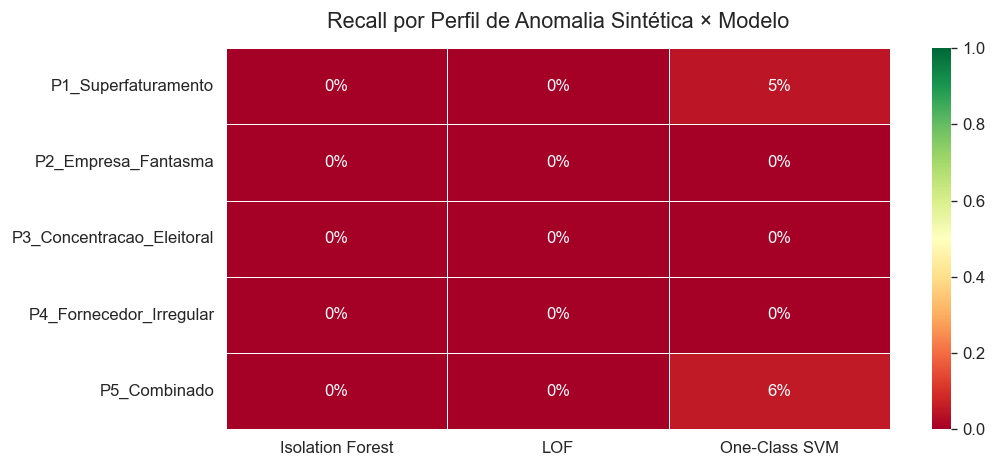

In [39]:
heatmap_data = df_recall.set_index('Perfil')[['Recall_IF', 'Recall_LOF', 'Recall_OCSVM']]
heatmap_data.columns = ['Isolation Forest', 'LOF', 'One-Class SVM']

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0%',
    cmap='RdYlGn',
    vmin=0, vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Recall por Perfil de Anomalia Sintética × Modelo', fontsize=13, pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### 6.2 Distribuição dos Scores — Real vs. Sintético

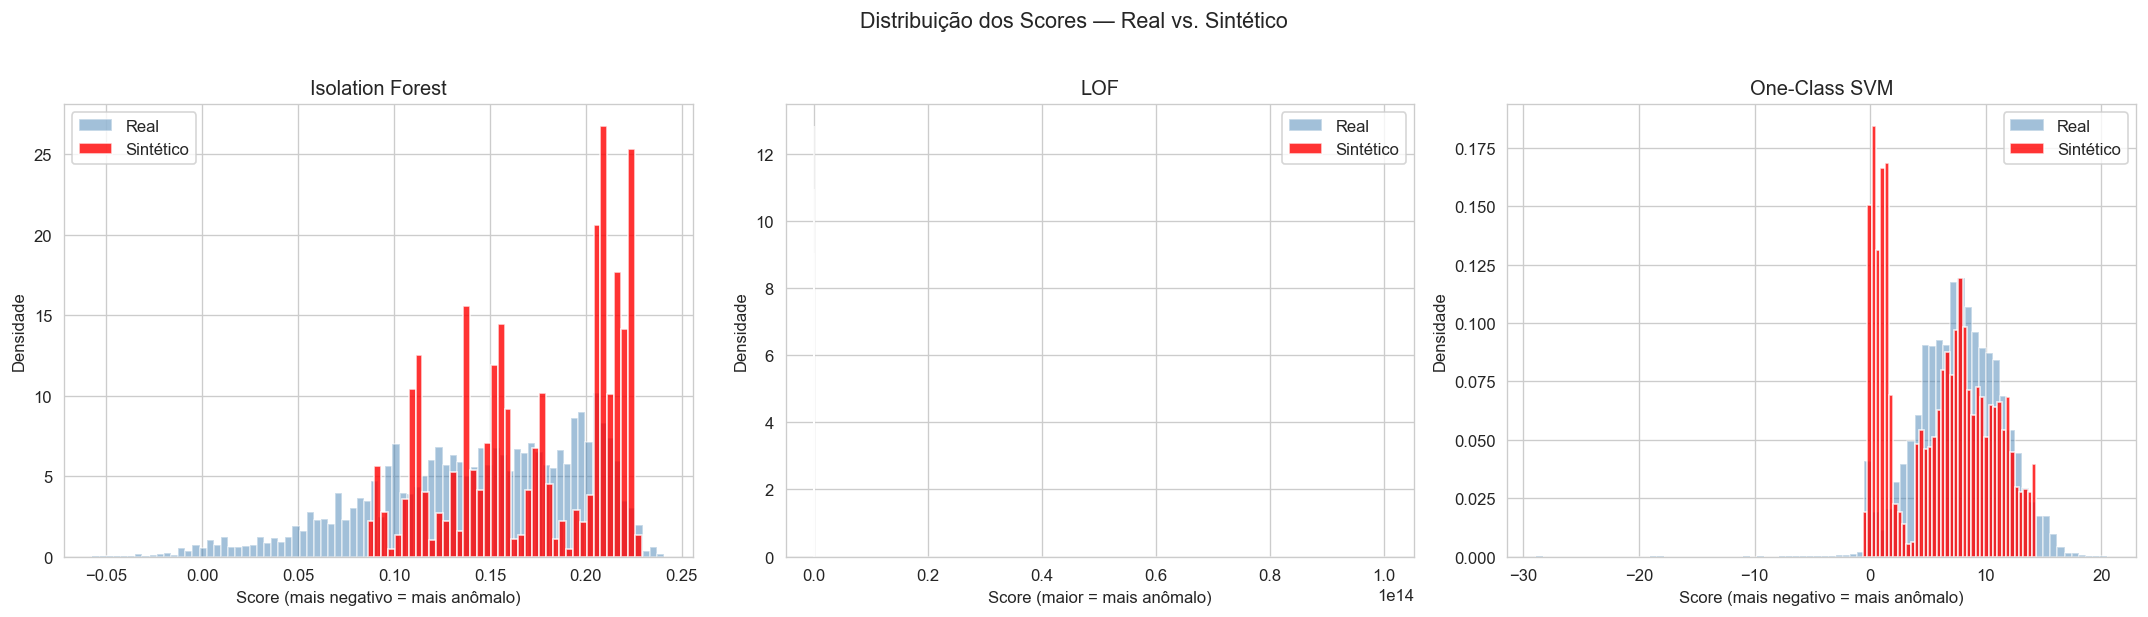

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

configs = [
    ('if_score',    'Isolation Forest',  'Score (mais negativo = mais anômalo)'),
    ('lof_score',   'LOF',               'Score (maior = mais anômalo)'),
    ('ocsvm_score', 'One-Class SVM',     'Score (mais negativo = mais anômalo)'),
]

for ax, (col, title, xlabel) in zip(axes, configs):
    real_scores = df_combined.loc[~df_combined['_sintetico'], col]
    sint_scores = df_combined.loc[ df_combined['_sintetico'], col]

    ax.hist(real_scores, bins=80, alpha=0.5, color='steelblue',
            density=True, label='Real')
    ax.hist(sint_scores, bins=40, alpha=0.8, color='red',
            density=True, label='Sintético')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Densidade')
    ax.legend()

plt.suptitle('Distribuição dos Scores — Real vs. Sintético', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

#### 6.3 Recall por Perfil — Gráfico de Barras Agrupadas

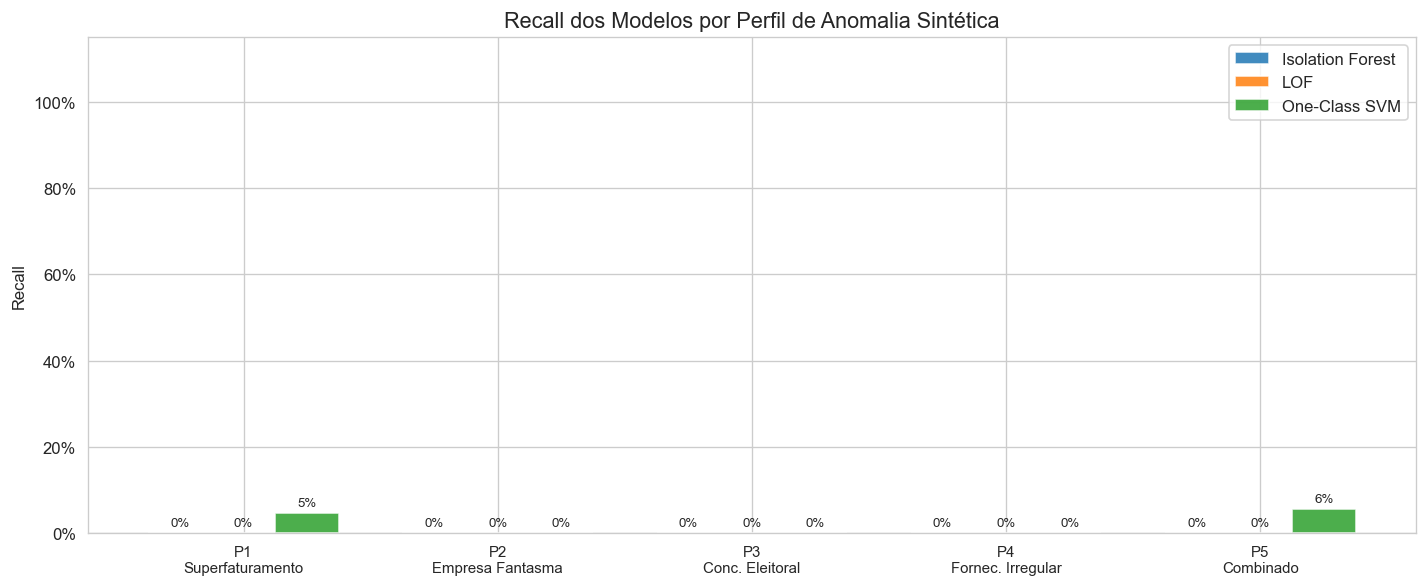

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))

x     = np.arange(len(perfis))
width = 0.25
cores = ['#1f77b4', '#ff7f0e', '#2ca02c']

labels_curtos = [
    'P1\nSuperfaturamento', 'P2\nEmpresa Fantasma',
    'P3\nConc. Eleitoral', 'P4\nFornec. Irregular', 'P5\nCombinado'
]

for i, (col, label, cor) in enumerate([
    ('Recall_IF',    'Isolation Forest', cores[0]),
    ('Recall_LOF',   'LOF',              cores[1]),
    ('Recall_OCSVM', 'One-Class SVM',    cores[2]),
]):
    bars = ax.bar(x + i * width, df_recall[col], width, label=label, color=cor, alpha=0.85)
    for bar, val in zip(bars, df_recall[col]):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{val:.0%}',
                ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(labels_curtos, fontsize=9)
ax.set_ylabel('Recall')
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Recall dos Modelos por Perfil de Anomalia Sintética', fontsize=13)
ax.legend()

plt.tight_layout()
plt.show()

#### 6.4 Score dos Sintéticos por Perfil (Boxplot)

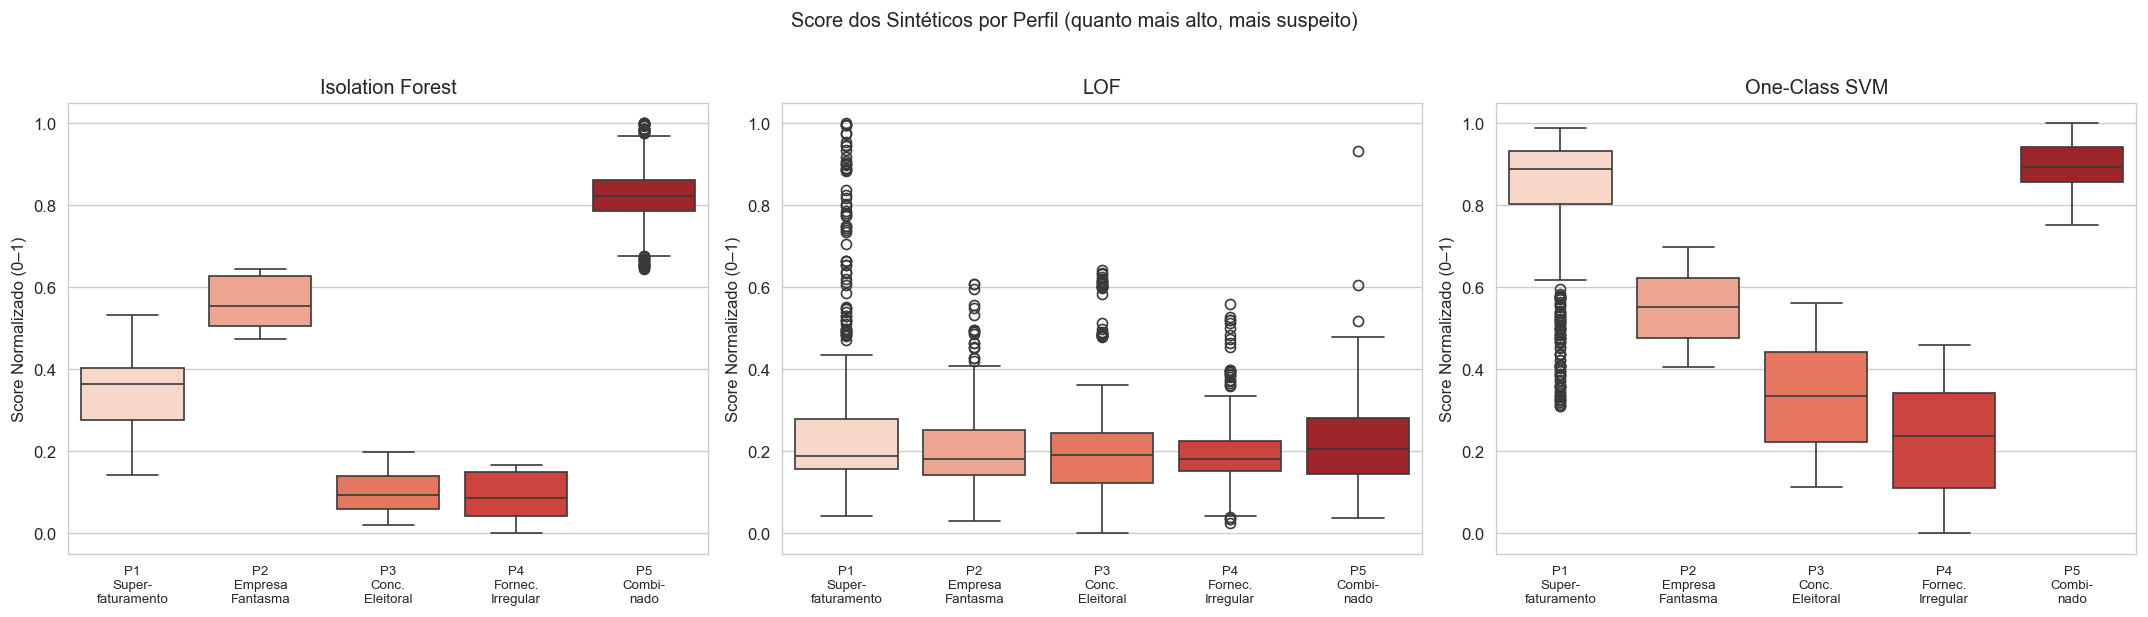

In [42]:
sint_df = df_combined[df_combined['_sintetico'] == True].copy()

# Normaliza IF e OCSVM (inverte sinal para que maior = mais anômalo)
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
sint_df['if_score_norm']    = mms.fit_transform(-sint_df[['if_score']])
sint_df['lof_score_norm']   = mms.fit_transform( sint_df[['lof_score']])
sint_df['ocsvm_score_norm'] = mms.fit_transform(-sint_df[['ocsvm_score']])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

score_configs = [
    ('if_score_norm',    'Isolation Forest'),
    ('lof_score_norm',   'LOF'),
    ('ocsvm_score_norm', 'One-Class SVM'),
]

perfil_order = ['P1_Superfaturamento', 'P2_Empresa_Fantasma',
                'P3_Concentracao_Eleitoral', 'P4_Fornecedor_Irregular', 'P5_Combinado']

for ax, (score_col, title) in zip(axes, score_configs):
    sns.boxplot(
        data=sint_df,
        x='_perfil', y=score_col,
        order=perfil_order,
        palette='Reds',
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Score Normalizado (0–1)')
    ax.set_xticklabels(
        ['P1\nSuper-\nfaturamento', 'P2\nEmpresa\nFantasma',
         'P3\nConc.\nEleitoral', 'P4\nFornec.\nIrregular', 'P5\nCombi-\nnado'],
        fontsize=8
    )

plt.suptitle('Score dos Sintéticos por Perfil (quanto mais alto, mais suspeito)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
### 7. Exportação dos Resultados

In [43]:
df_recall.to_csv('data/output/recall_sinteticos.csv', index=False)
print('Salvo: data/output/recall_sinteticos.csv')

sint_export = df_combined[df_combined['_sintetico'] == True][[
    '_perfil',
    'if_score',    'if_label',
    'lof_score',   'lof_label',
    'ocsvm_score', 'ocsvm_label',
    'votos'
]].copy()
sint_export.to_csv('data/output/sinteticos_detalhado.csv', index=False)
print('Salvo: data/output/sinteticos_detalhado.csv')

print()
print('=== Resumo Final ===')
print(df_recall[['Perfil', 'Recall_IF', 'Recall_LOF', 'Recall_OCSVM', 'Recall_Médio']]
      .to_string(index=False, float_format=lambda x: f'{x:.1%}'))

Salvo: data/output/recall_sinteticos.csv
Salvo: data/output/sinteticos_detalhado.csv

=== Resumo Final ===
                   Perfil  Recall_IF  Recall_LOF  Recall_OCSVM  Recall_Médio
      P1_Superfaturamento       0.0%        0.0%          4.6%          1.5%
      P2_Empresa_Fantasma       0.0%        0.0%          0.0%          0.0%
P3_Concentracao_Eleitoral       0.0%        0.0%          0.0%          0.0%
  P4_Fornecedor_Irregular       0.0%        0.0%          0.0%          0.0%
             P5_Combinado       0.0%        0.0%          5.6%          1.9%


---
### 8. Comparação com o Ranking de Risco (NB09)

Onde os sintéticos cairiam no ranking real? Esta seção calcula o `score_combinado` para
os sintéticos usando a mesma metodologia do NB09 (MinMax nos 3 scores, média) e os
posiciona dentro da distribuição do ranking original.

In [44]:
# Calcula score_combinado para o dataset completo (real + sintético)
# usando MinMax global — mesma lógica do NB09
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()
df_combined['if_score_norm']    = mms.fit_transform(-df_combined[['if_score']])
df_combined['lof_score_norm']   = mms.fit_transform( df_combined[['lof_score']])
df_combined['ocsvm_score_norm'] = mms.fit_transform(-df_combined[['ocsvm_score']])

df_combined['score_combinado'] = df_combined[[
    'if_score_norm', 'lof_score_norm', 'ocsvm_score_norm'
]].mean(axis=1)

# Ranking geral (real + sintético), ordenado por votos e score
df_rank_full = df_combined.sort_values(
    ['votos', 'score_combinado'], ascending=[False, False]
).reset_index(drop=True)
df_rank_full['posicao'] = df_rank_full.index + 1

n_total = len(df_rank_full)
sint_ranked = df_rank_full[df_rank_full['_sintetico'] == True].copy()

print(f'Total no ranking: {n_total}')
print(f'Sintéticos incluídos: {len(sint_ranked)}')
print()
print('=== Posição mediana dos sintéticos no ranking combinado ===')
for perfil in perfis:
    subset = sint_ranked[sint_ranked['_perfil'] == perfil]
    med_pos  = subset['posicao'].median()
    min_pos  = subset['posicao'].min()
    pct      = med_pos / n_total * 100
    print(f'  {perfil:<35s} → posição mediana: {med_pos:>7.0f} / {n_total}  ({pct:.1f}% do ranking)'
          f'  | melhor posição: {min_pos:.0f}')

Total no ranking: 78718
Sintéticos incluídos: 2500

=== Posição mediana dos sintéticos no ranking combinado ===
  P1_Superfaturamento                 → posição mediana:   31139 / 78718  (39.6% do ranking)  | melhor posição: 2212
  P2_Empresa_Fantasma                 → posição mediana:   33956 / 78718  (43.1% do ranking)  | melhor posição: 24953
  P3_Concentracao_Eleitoral           → posição mediana:   71030 / 78718  (90.2% do ranking)  | melhor posição: 54192
  P4_Fornecedor_Irregular             → posição mediana:   73569 / 78718  (93.5% do ranking)  | melhor posição: 60185
  P5_Combinado                        → posição mediana:   12320 / 78718  (15.7% do ranking)  | melhor posição: 1927


#### 8.2 Distribuição de Posição por Perfil no Ranking

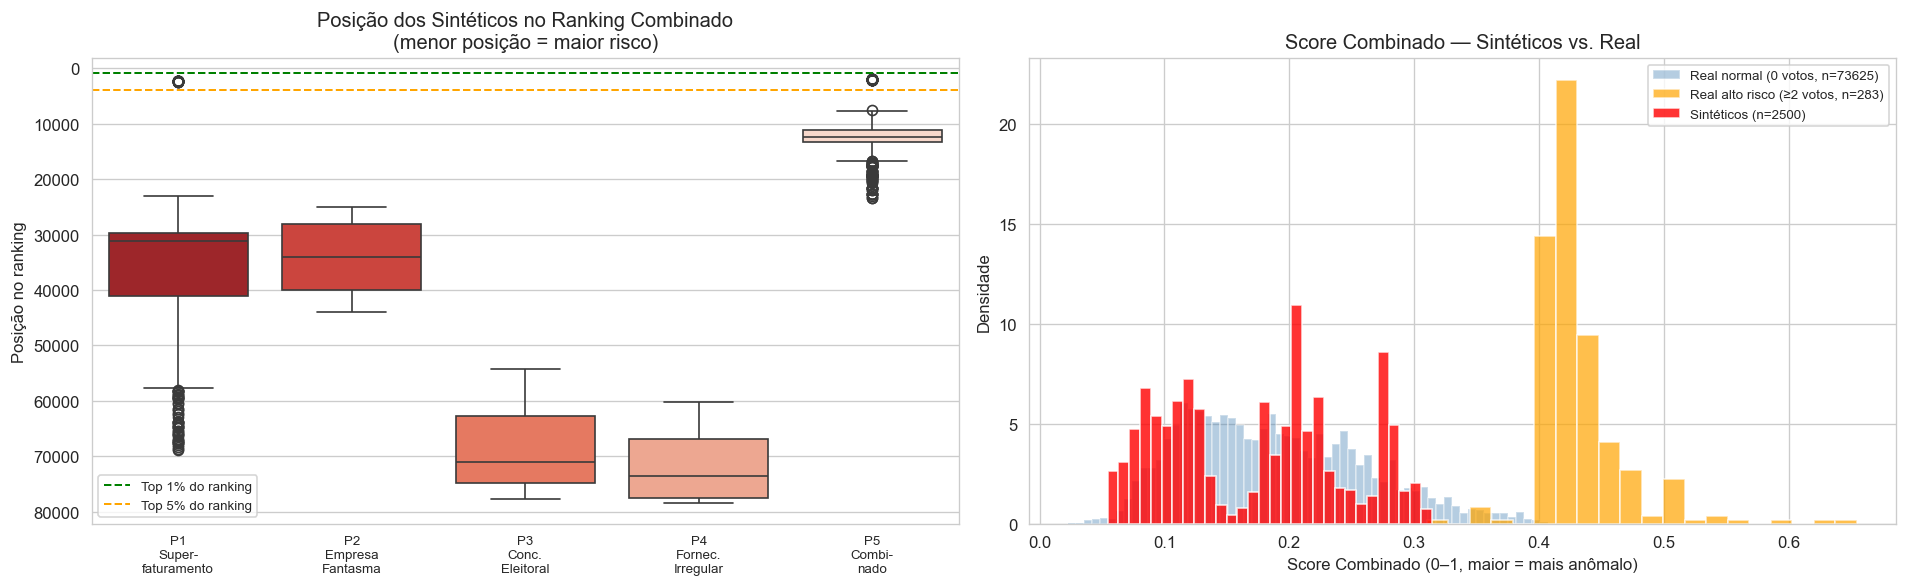

Figura salva em data/output/fig_ranking_sinteticos.png


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Boxplot: distribuição de posição por perfil ---
sns.boxplot(
    data=sint_ranked,
    x='_perfil', y='posicao',
    order=perfis,
    palette='Reds_r',
    ax=axes[0]
)
axes[0].axhline(n_total * 0.01, color='green', linestyle='--', linewidth=1.2,
                label='Top 1% do ranking')
axes[0].axhline(n_total * 0.05, color='orange', linestyle='--', linewidth=1.2,
                label='Top 5% do ranking')
axes[0].set_title('Posição dos Sintéticos no Ranking Combinado\n(menor posição = maior risco)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Posição no ranking')
axes[0].set_xticklabels(
    ['P1\nSuper-\nfaturamento', 'P2\nEmpresa\nFantasma',
     'P3\nConc.\nEleitoral', 'P4\nFornec.\nIrregular', 'P5\nCombi-\nnado'],
    fontsize=8
)
axes[0].legend(fontsize=8)
axes[0].invert_yaxis()  # posição 1 no topo

# --- Score combinado: sintéticos vs. real de alto risco ---
real_alto   = df_rank_full[(~df_rank_full['_sintetico']) & (df_rank_full['votos'] >= 2)]
real_normal = df_rank_full[(~df_rank_full['_sintetico']) & (df_rank_full['votos'] == 0)]

axes[1].hist(real_normal['score_combinado'], bins=60, alpha=0.4,
             color='steelblue', density=True, label=f'Real normal (0 votos, n={len(real_normal)})')
axes[1].hist(real_alto['score_combinado'], bins=20, alpha=0.7,
             color='orange', density=True, label=f'Real alto risco (≥2 votos, n={len(real_alto)})')
axes[1].hist(sint_ranked['score_combinado'], bins=30, alpha=0.8,
             color='red', density=True, label=f'Sintéticos (n={len(sint_ranked)})')
axes[1].set_title('Score Combinado — Sintéticos vs. Real')
axes[1].set_xlabel('Score Combinado (0–1, maior = mais anômalo)')
axes[1].set_ylabel('Densidade')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/output/fig_ranking_sinteticos.png', bbox_inches='tight')
plt.show()
print('Figura salva em data/output/fig_ranking_sinteticos.png')

#### 8.3 Top-20 do Ranking Combinado — Quais são sintéticos?

In [46]:
top20 = df_rank_full.head(20)[[
    'posicao', '_sintetico', '_perfil', 'votos', 'score_combinado',
    'desvio_item_estimado', 'empresa_nova', 'pre_eleitoral_180d',
    'fornecedor_fora_pe', 'descricao_situacao_cadastral'
]].copy()

top20['origem'] = top20['_sintetico'].map({True: '🔴 SINTÉTICO', False: '🔵 real'})

n_sint_top20 = top20['_sintetico'].sum()
print(f'=== Top-20 do Ranking Combinado ===')
print(f'Sintéticos no top-20: {n_sint_top20} / 20\n')
print(top20[['posicao', 'origem', '_perfil', 'votos', 'score_combinado',
             'desvio_item_estimado']].to_string(index=False))

print(f'\n=== Sintéticos no Top 1% ({int(n_total*0.01)} posições) ===')
sint_top1pct = sint_ranked[sint_ranked['posicao'] <= n_total * 0.01]
print(f'Total: {len(sint_top1pct)} sintéticos')
if len(sint_top1pct) > 0:
    print(sint_top1pct[['posicao', '_perfil', 'votos', 'score_combinado']].to_string(index=False))

=== Top-20 do Ranking Combinado ===
Sintéticos no top-20: 0 / 20

 posicao origem _perfil  votos  score_combinado  desvio_item_estimado
       1 🔵 real    real      3         0.654414             -0.235096
       2 🔵 real    real      3         0.623484             -0.071574
       3 🔵 real    real      3         0.447636             -0.006879
       4 🔵 real    real      3         0.427687              0.000000
       5 🔵 real    real      3         0.427687              0.000000
       6 🔵 real    real      3         0.427687              0.000000
       7 🔵 real    real      3         0.427687              0.000000
       8 🔵 real    real      3         0.427687              0.000000
       9 🔵 real    real      3         0.427687              0.000000
      10 🔵 real    real      3         0.427687              0.000000
      11 🔵 real    real      3         0.427687              0.000000
      12 🔵 real    real      3         0.427687              0.000000
      13 🔵 real    real 

---
### 9. Interpretação e Próximos Passos

**O que os resultados indicam:**

- Um recall alto em P5 (Combinado) confirma que os modelos respondem ao acúmulo de sinais de anomalia — comportamento esperado e teoricamente coerente.
- Perfis com recall baixo indicam que o modelo tem dificuldade em distinguir aquele padrão do comportamento normal do dataset — pode ser sinal de que a feature isolada não é suficientemente discriminante, ou que o comportamento está presente também nos dados reais.
- Diferenças de recall entre os 3 modelos revelam o **viés de cada algoritmo**: IF é sensível a isolamento global, LOF a densidade local, OCSVM a separabilidade no espaço transformado.

**Limitação principal:**

- Os dados sintéticos são construídos a partir de hipóteses sobre padrões fraudulentos, não de fraudes confirmadas — medem a *sensibilidade aos perfis definidos*, não a precisão real.
- O `desvio_item_estimado` mostrou ser a feature com maior poder discriminante. Variáveis binárias e categóricas por si só (`empresa_nova`, `pre_eleitoral_180d`, `fornecedor_fora_pe`) não geram sinal suficiente para romper a fronteira de decisão dos modelos — o que pode indicar que esses padrões já existem na base real com frequência.